# Buying Different Tech Stocks, or Buying the Same Risk Repeatedly?

**Diversification, common risk, downside exposure and portfolio construction**  
Octavio Adolfo Ramos Calderón · Independent quantitative finance research · October 2026

Eight technology-related equities: **AAPL, MSFT, NVDA, META, GOOGL, AMD, TSM, ASML**. Benchmarks: **SPY** and **XLK**.

This notebook reproduces a historical research workflow, not a trading signal. The universe was chosen with hindsight. Figures may differ slightly from the accompanying report if Yahoo Finance revises historical data or the implementation conventions differ. No costs, taxes, financing, slippage or market impact are included.

## 1. Data and conventions

- **Sample:** January 2020 to 30 September 2026 (inclusive); USD-adjusted daily closes.
- **Training:** 2020–2023. **Held-out evaluation:** 2024–September 2026.
- **Portfolios:** fully invested, long-only, maximum 35% in any single security.
- **Risk:** daily simple returns; sample covariance; 252 trading days per year.
- **Execution convention:** weights selected at the end of training, held fixed as targets; daily rebalancing is the baseline, monthly rebalancing is a sensitivity check.
- **Performance:** geometric annualized returns from daily portfolio returns. CVaR is the mean daily *loss* in the worst 5% of observations.

All assets are aligned on common trading dates. This facilitates comparison but excludes sessions in which any instrument lacks a price.

In [1]:
%pip -q install yfinance numpy pandas scipy scikit-learn matplotlib

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from scipy.optimize import minimize, linprog
from sklearn.decomposition import PCA

STOCKS = ["AAPL", "MSFT", "NVDA", "META", "GOOGL", "AMD", "TSM", "ASML"]
BENCHMARKS = ["SPY", "XLK"]
TICKERS = STOCKS + BENCHMARKS
START, END = "2020-01-01", "2026-10-01"  # yfinance end is exclusive
TRAIN_END = "2023-12-31"
ANNUALIZATION = 252
POSITION_CAP = 0.35
OUTPUT = Path("outputs")
OUTPUT.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
np.set_printoptions(precision=5, suppress=True)

In [3]:
# Download tickers individually to avoid version-specific multi-index issues.
series = {}
for ticker in TICKERS:
    frame = yf.download(ticker, start=START, end=END, auto_adjust=True,
                        progress=False, actions=False, threads=False)
    if frame.empty:
        raise RuntimeError(f"No observations returned for {ticker}.")
    close = frame["Close"]
    if isinstance(close, pd.DataFrame):
        close = close.iloc[:, 0]
    series[ticker] = close.rename(ticker)

prices = pd.concat(series.values(), axis=1).sort_index().dropna(how="any")
returns = prices.pct_change().dropna()
train = returns.loc[:TRAIN_END, STOCKS]
test = returns.loc["2024-01-01":, STOCKS]
if train.empty or test.empty:
    raise RuntimeError("Check sample dates: training or test returns are empty.")
print(f"Aligned prices: {len(prices):,} | returns: {len(returns):,}")
print(f"Training: {len(train):,} observations | Test: {len(test):,} observations")
print(f"Price dates: {prices.index.min().date()} to {prices.index.max().date()}")

Aligned prices: 1,695 | returns: 1,694
Training: 1,005 observations | Test: 689 observations
Price dates: 2020-01-02 to 2026-09-30


## 2. Baseline diversification

Correlations are calculated on **returns**, not prices. The equal-weight basket is assumed to rebalance daily; therefore its daily return is the dot product of stock returns and fixed target weights.

Average pairwise correlation: 0.549
Mean constituent volatility: 41.10%
Equal-weight portfolio volatility: 32.17%
Relative volatility reduction: 21.7%


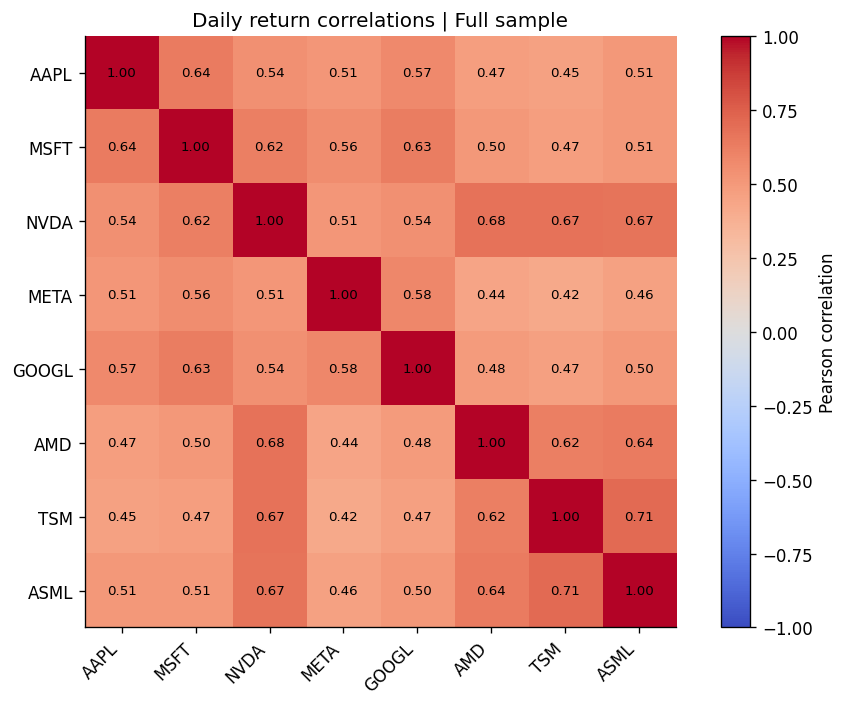

In [4]:
def annual_volatility(r):
    return float(pd.Series(r).std(ddof=1) * np.sqrt(ANNUALIZATION))

def max_drawdown(r):
    wealth = (1 + pd.Series(r)).cumprod()
    return float((wealth / wealth.cummax() - 1).min())

def cvar_loss(r, alpha=0.95):
    losses = -np.asarray(r, dtype=float)
    var = np.quantile(losses, alpha)
    return float(losses[losses >= var].mean())

def annualized_growth(r):
    r = np.asarray(r, dtype=float)
    return float(np.prod(1 + r) ** (ANNUALIZATION / len(r)) - 1)

def average_pairwise_correlation(r):
    matrix = pd.DataFrame(r).corr().to_numpy()
    return float(matrix[np.triu_indices_from(matrix, k=1)].mean())

weights_equal = np.repeat(1 / len(STOCKS), len(STOCKS))
full = returns[STOCKS]
full_ew = pd.Series(full.to_numpy() @ weights_equal, index=full.index, name="Equal Weight")
mean_constituent_vol = full.std().mean() * np.sqrt(ANNUALIZATION)
print(f"Average pairwise correlation: {average_pairwise_correlation(full):.3f}")
print(f"Mean constituent volatility: {mean_constituent_vol:.2%}")
print(f"Equal-weight portfolio volatility: {annual_volatility(full_ew):.2%}")
print(f"Relative volatility reduction: {1-annual_volatility(full_ew)/mean_constituent_vol:.1%}")

corr = full.corr()
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(STOCKS)), STOCKS, rotation=45, ha="right")
ax.set_yticks(range(len(STOCKS)), STOCKS)
for i in range(len(STOCKS)):
    for j in range(len(STOCKS)):
        ax.text(j, i, f"{corr.iloc[i,j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax, label="Pearson correlation")
ax.set_title("Daily return correlations | Full sample")
fig.tight_layout()
fig.savefig(OUTPUT / "01_correlation.png", bbox_inches="tight")
plt.show()

## 3. Principal Component Analysis

PCA uses *standardized* returns, so it analyzes the correlation structure rather than giving extra weight to higher-volatility securities. **Effective participation dimension** summarizes eigenvalue concentration: it is not a count of independently identified economic factors.

Full-sample PCA: {'PC1': np.float64(0.6066760787542177), 'PC1 + PC2': np.float64(0.720162834407704), 'Effective dimension': np.float64(2.534351394738255)}
                  PC1  PC1 + PC2  Effective dimension
2020–2021      0.6906     0.7858               2.0214
2022–2023      0.6918     0.7843               2.0178
2024–Sep 2026  0.4785     0.6165               3.6374


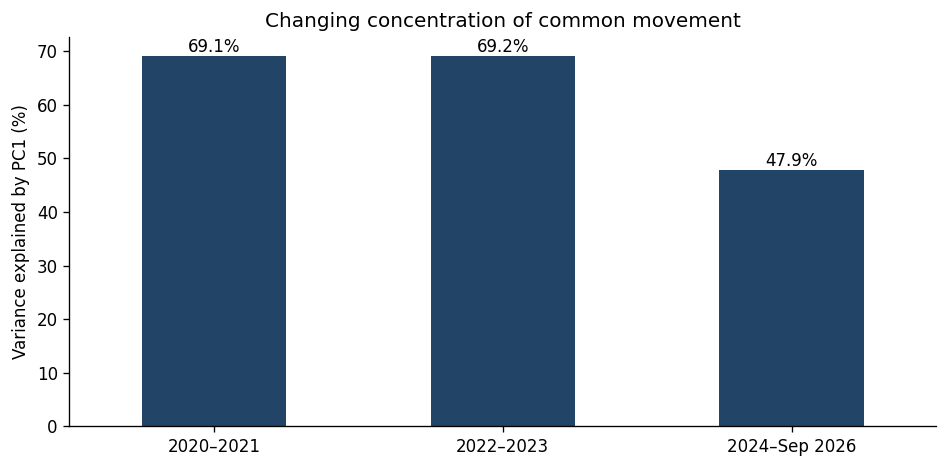

In [5]:
def pca_summary(r):
    standardized = (r - r.mean()) / r.std(ddof=1)
    pca = PCA().fit(standardized)
    explained = pca.explained_variance_ratio_
    effective_dim = 1 / np.sum(explained ** 2)
    return {"PC1": explained[0], "PC1 + PC2": explained[:2].sum(),
            "Effective dimension": effective_dim}

periods = {
    "2020–2021": full.loc["2020":"2021"],
    "2022–2023": full.loc["2022":"2023"],
    "2024–Sep 2026": full.loc["2024":"2026-09-30"],
}
pca_table = pd.DataFrame({name: pca_summary(r) for name, r in periods.items()}).T
print("Full-sample PCA:", pca_summary(full))
print(pca_table.round(4).to_string())
ax = (100 * pca_table["PC1"]).plot(kind="bar", figsize=(8, 4), color="#224466", rot=0)
ax.set(ylabel="Variance explained by PC1 (%)", title="Changing concentration of common movement")
for bar in ax.patches:
    ax.annotate(f"{bar.get_height():.1f}%", (bar.get_x()+bar.get_width()/2, bar.get_height()),
                ha="center", va="bottom")
plt.tight_layout()
plt.savefig(OUTPUT / "02_pca_stability.png", bbox_inches="tight")
plt.show()

## 4. Where does portfolio volatility come from?

Euler contributions to volatility add up to total volatility. The normalized risk shares are computed from \(w_i(\Sigma w)_i / (w^T\Sigma w)\), using the **full-sample** annualized covariance matrix. These are *ex-post descriptive* attributions, not forecasts.

       Capital weight  Volatility contribution
AMD              12.5                    17.71
NVDA             12.5                    17.30
ASML             12.5                    13.81
META             12.5                    12.13
TSM              12.5                    11.93
GOOGL            12.5                     9.33
MSFT             12.5                     9.00
AAPL             12.5                     8.79


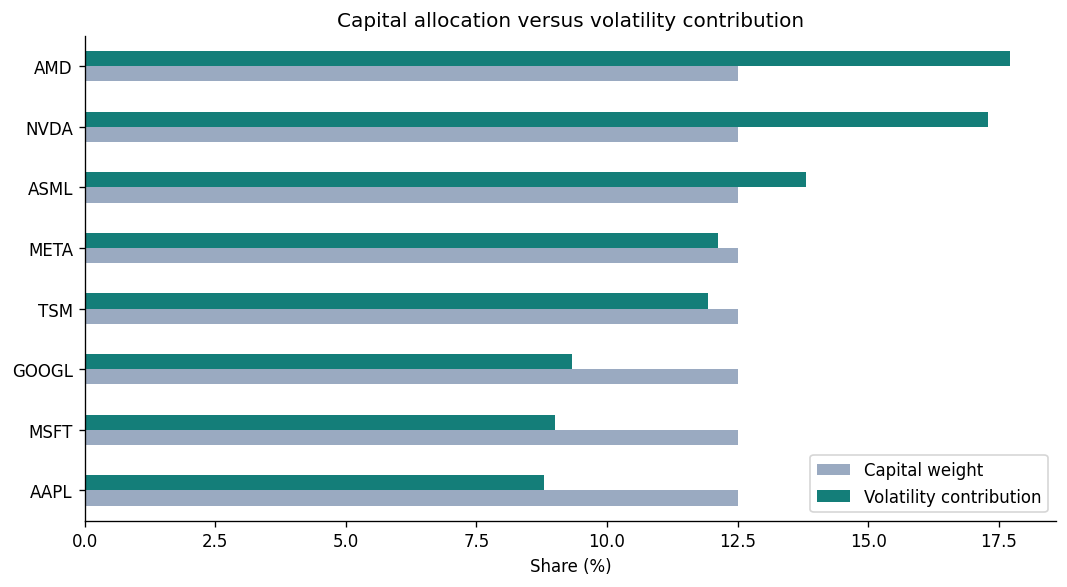

In [6]:
cov_full = full.cov().to_numpy() * ANNUALIZATION
portfolio_variance = weights_equal @ cov_full @ weights_equal
risk_share = weights_equal * (cov_full @ weights_equal) / portfolio_variance
risk_attribution = pd.DataFrame({"Capital weight": weights_equal,
                                 "Volatility contribution": risk_share}, index=STOCKS)
assert np.isclose(risk_share.sum(), 1.0)
print((risk_attribution * 100).round(2).sort_values("Volatility contribution", ascending=False))
plot_data = risk_attribution.sort_values("Volatility contribution") * 100
ax = plot_data.plot.barh(figsize=(9, 5), color=["#9aaac1", "#147e79"])
ax.set(xlabel="Share (%)", title="Capital allocation versus volatility contribution")
plt.tight_layout()
plt.savefig(OUTPUT / "03_risk_contributions.png", bbox_inches="tight")
plt.show()

## 5. Historical stress windows

Events are **selected in hindsight**, and the COVID crash window is much shorter than the annual windows. The comparisons describe these specific periods, not a universal law that correlations always rise in a downturn.

                    Observations  Mean correlation  Annualized volatility  Cumulative return  Max drawdown
Window                                                                                                    
COVID crash (2020)            24            0.8738                 0.8817            -0.2690       -0.2987
Bear market (2022)           251            0.7140                 0.4218            -0.4063       -0.4893
Recovery (2023)              250            0.5030                 0.2591             0.9514       -0.1269


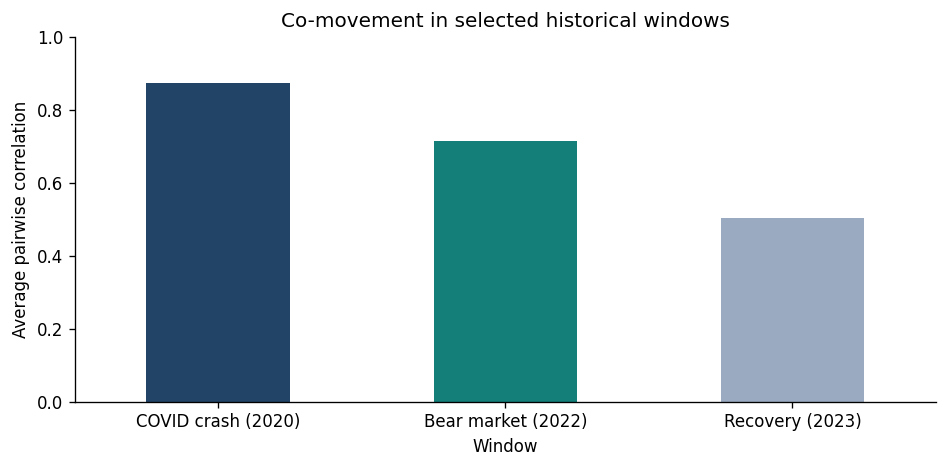

In [7]:
stress_windows = {
    "COVID crash (2020)": ("2020-02-19", "2020-03-23"),
    "Bear market (2022)": ("2022-01-01", "2022-12-31"),
    "Recovery (2023)": ("2023-01-01", "2023-12-31"),
}
stress_rows = []
for name, (start, end) in stress_windows.items():
    sub = full.loc[start:end]
    basket = pd.Series(sub.to_numpy() @ weights_equal, index=sub.index)
    stress_rows.append({"Window": name, "Observations": len(sub),
                        "Mean correlation": average_pairwise_correlation(sub),
                        "Annualized volatility": annual_volatility(basket),
                        "Cumulative return": float((1 + basket).prod() - 1),
                        "Max drawdown": max_drawdown(basket)})
stress = pd.DataFrame(stress_rows).set_index("Window")
print(stress.round(4).to_string())
ax = stress["Mean correlation"].plot.bar(figsize=(8, 4), rot=0, color=["#224466", "#147e79", "#9aaac1"])
ax.set(ylabel="Average pairwise correlation", ylim=(0, 1), title="Co-movement in selected historical windows")
plt.tight_layout()
plt.savefig(OUTPUT / "04_stress_correlations.png", bbox_inches="tight")
plt.show()

## 6. Portfolio construction (training sample only)

**Minimum Variance:** constrained quadratic optimization. **Minimum CVaR:** Rockafellar–Uryasev historical linear program at 95% confidence. Both are long-only and fully invested with an individual 35% upper bound. No target expected return is imposed. Optimization uses **training observations exclusively**.

In [8]:
def optimize_min_variance(r, cap=POSITION_CAP):
    n_assets = r.shape[1]
    cov = r.cov().to_numpy() * ANNUALIZATION
    initial = np.repeat(1 / n_assets, n_assets)
    solution = minimize(lambda w: w @ cov @ w, initial,
                        jac=lambda w: 2 * cov @ w,
                        method="SLSQP", bounds=[(0, cap)] * n_assets,
                        constraints=[{"type": "eq", "fun": lambda w: w.sum() - 1,
                                      "jac": lambda w: np.ones_like(w)}],
                        options={"ftol": 1e-12, "maxiter": 10000})
    if not solution.success:
        raise RuntimeError(f"Minimum variance failed: {solution.message}")
    return solution.x

def optimize_min_cvar(r, alpha=0.95, cap=POSITION_CAP):
    # Variables = n weights, one free VaR threshold t, and T non-negative slack variables.
    R = r.to_numpy(dtype=float)
    T, n_assets = R.shape
    objective = np.r_[np.zeros(n_assets), 1.0, np.repeat(1 / ((1-alpha)*T), T)]
    # -R_t w - t <= u_t   ==>   -R_t w - t - u_t <= 0
    inequalities = np.hstack([-R, -np.ones((T, 1)), -np.eye(T)])
    equality = np.r_[np.ones(n_assets), np.zeros(T+1)].reshape(1, -1)
    bounds = [(0, cap)]*n_assets + [(None, None)] + [(0, None)]*T
    solution = linprog(objective, A_ub=inequalities, b_ub=np.zeros(T),
                       A_eq=equality, b_eq=np.array([1.0]),
                       bounds=bounds, method="highs")
    if not solution.success:
        raise RuntimeError(f"Minimum CVaR failed: {solution.message}")
    return solution.x[:n_assets]

portfolios = {
    "Equal Weight": weights_equal,
    "Minimum Variance": optimize_min_variance(train),
    "Minimum CVaR": optimize_min_cvar(train),
}
weights = pd.DataFrame(portfolios, index=STOCKS)
assert np.allclose(weights.sum(axis=0), 1)
assert weights.to_numpy().min() >= -1e-8
assert weights.to_numpy().max() <= POSITION_CAP + 1e-8
print((weights*100).round(2).to_string())
weights.to_csv(OUTPUT / "portfolio_weights.csv")

       Equal Weight  Minimum Variance  Minimum CVaR
AAPL           12.5             24.33         18.81
MSFT           12.5             25.85         26.48
NVDA           12.5              0.00          0.00
META           12.5              0.00          0.00
GOOGL          12.5             26.68         19.72
AMD            12.5              0.00          0.00
TSM            12.5             23.14         35.00
ASML           12.5              0.00          0.00


## 7. Held-out performance: daily target-weight rebalancing

The daily strategy sets the portfolio return to the weighted sum of individual daily returns. This assumes frictionless trading to restore the target weights **every session**. Optimized weights are never refitted in the test period.

                  Annual return  Annual volatility  Daily VaR 95%  Daily CVaR 95%  Max drawdown
Equal Weight              50.01              28.08           2.63            3.81        -28.99
Minimum Variance          38.22              22.36           2.06            3.08        -26.79
Minimum CVaR              42.87              23.96           2.23            3.27        -27.70


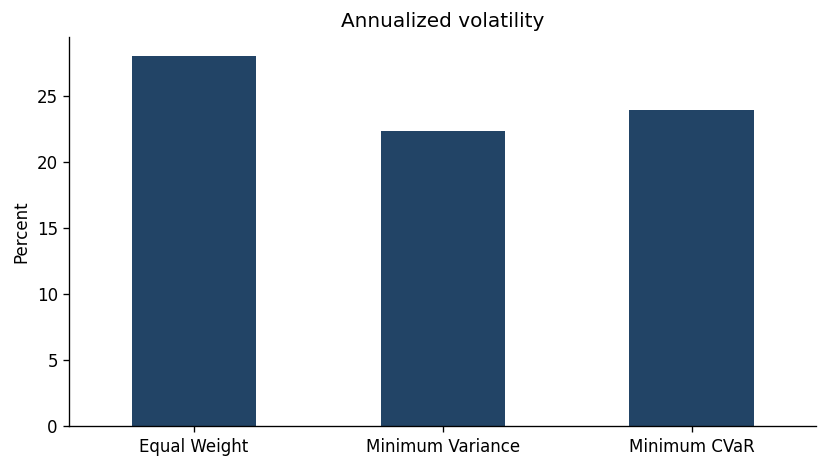

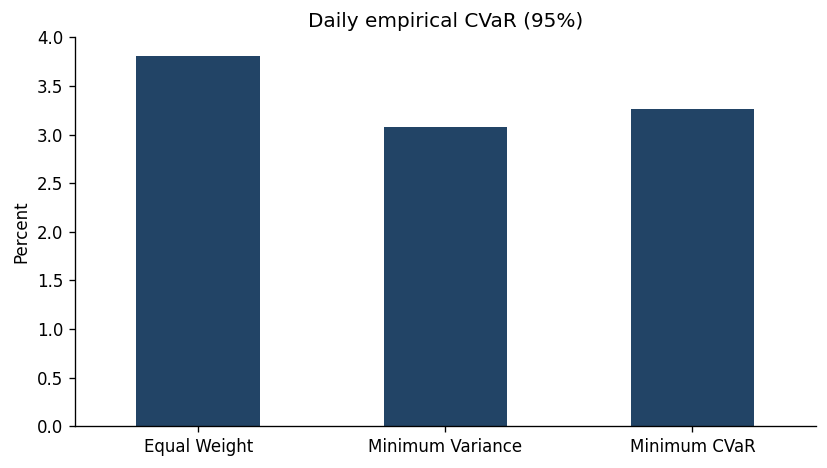

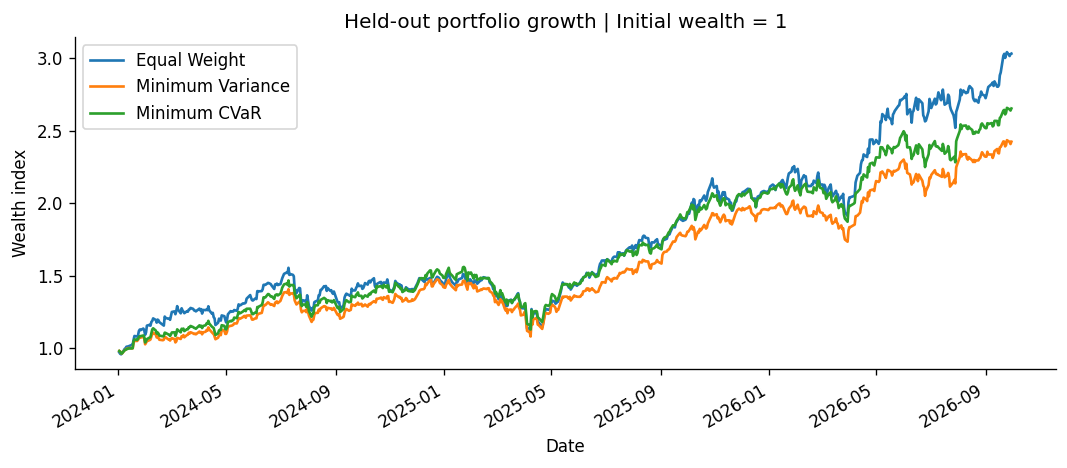

In [9]:
oos_daily = pd.DataFrame({name: test.to_numpy() @ w
                          for name, w in portfolios.items()}, index=test.index)

def performance_table(returns_by_portfolio):
    return pd.DataFrame({name: {
        "Annual return": annualized_growth(r),
        "Annual volatility": annual_volatility(r),
        "Daily VaR 95%": float(np.quantile(-np.asarray(r), 0.95)),
        "Daily CVaR 95%": cvar_loss(r),
        "Max drawdown": max_drawdown(r),
    } for name, r in returns_by_portfolio.items()}).T

performance = performance_table(oos_daily)
print((100 * performance).round(2).to_string())
performance.to_csv(OUTPUT / "test_performance.csv")

for column, filename, heading in [
    ("Annual volatility", "05a_annual_volatility.png", "Annualized volatility"),
    ("Daily CVaR 95%", "05b_daily_cvar.png", "Daily empirical CVaR (95%)"),
]:
    ax = (100 * performance[column]).plot.bar(figsize=(7, 4), rot=0, color="#224466")
    ax.set(ylabel="Percent", title=heading)
    plt.tight_layout()
    plt.savefig(OUTPUT / filename, bbox_inches="tight")
    plt.show()

wealth = (1 + oos_daily).cumprod()
ax = wealth.plot(figsize=(9, 4), lw=1.6, title="Held-out portfolio growth | Initial wealth = 1")
ax.set_ylabel("Wealth index")
plt.tight_layout()
plt.savefig(OUTPUT / "06_test_wealth.png", bbox_inches="tight")
plt.show()

## 8. Benchmark exposure: separate SPY and XLK regressions

Single-factor OLS slopes use synchronized daily test returns. Beta and R² describe association **with that benchmark alone**; the XLK beta is not an incremental sector effect after controlling for SPY. XLK is not a complete representation of the multinational/communications-heavy stock universe.

In [10]:
benchmark_test = returns.loc[test.index, BENCHMARKS]
betas = []
for name in oos_daily.columns:
    y = oos_daily[name]
    for benchmark in BENCHMARKS:
        x = benchmark_test[benchmark]
        beta = float(np.cov(y, x, ddof=1)[0, 1] / np.var(x, ddof=1))
        correlation = float(y.corr(x))
        betas.append({"Portfolio": name, "Benchmark": benchmark,
                      "Beta": beta, "Correlation": correlation, "R-squared": correlation**2})
benchmark_exposure = pd.DataFrame(betas).set_index(["Portfolio", "Benchmark"])
print(benchmark_exposure.round(3).to_string())
benchmark_exposure.to_csv(OUTPUT / "benchmark_exposure.csv")

                             Beta  Correlation  R-squared
Portfolio        Benchmark                               
Equal Weight     SPY        1.558        0.863      0.745
                 XLK        0.992        0.913      0.834
Minimum Variance SPY        1.211        0.842      0.710
                 XLK        0.708        0.819      0.671
Minimum CVaR     SPY        1.280        0.831      0.691
                 XLK        0.786        0.848      0.719


## 9. Rebalancing sensitivity

Under monthly rebalancing, weights drift with returns and are reset at the **start of the first observed session in each calendar month**. The daily case resets each session. Results exclude transaction costs; this is not a net implementable return.

In [11]:
def portfolio_path(asset_returns, target_weights, frequency="monthly"):
    current = np.asarray(target_weights, dtype=float).copy()
    pnl = []
    previous_month = None
    for date, row in asset_returns.iterrows():
        if frequency == "daily" or previous_month != date.to_period("M"):
            current = np.asarray(target_weights, dtype=float).copy()
        r = row.to_numpy(dtype=float)
        period_return = float(current @ r)
        pnl.append(period_return)
        current = current * (1 + r) / (1 + period_return)
        previous_month = date.to_period("M")
    return pd.Series(pnl, index=asset_returns.index)

monthly = pd.DataFrame({name: portfolio_path(test, w, "monthly")
                        for name, w in portfolios.items()})
daily_check = pd.DataFrame({name: portfolio_path(test, w, "daily")
                            for name, w in portfolios.items()})
assert np.allclose(daily_check.to_numpy(), oos_daily.to_numpy())
comparison = pd.DataFrame({
    "Daily annual return": oos_daily.apply(annualized_growth),
    "Monthly annual return": monthly.apply(annualized_growth),
    "Daily annual volatility": oos_daily.apply(annual_volatility),
    "Monthly annual volatility": monthly.apply(annual_volatility),
})
print((comparison*100).round(2).to_string())
comparison.to_csv(OUTPUT / "rebalancing_comparison.csv")

                  Daily annual return  Monthly annual return  Daily annual volatility  Monthly annual volatility
Equal Weight                    50.01                  49.99                    28.08                      28.13
Minimum Variance                38.22                  37.88                    22.36                      22.37
Minimum CVaR                    42.87                  42.47                    23.96                      24.03


## 10. Reproducibility and interpretation

**Main finding.** A basket of related stocks can diversify individual-security volatility without delivering eight independent sources of risk. PCA concentration, unequal risk contributions and positive benchmark exposure are complementary descriptions; none identifies an underlying causal economic factor on its own.

**Limitations.** Ex-post asset selection and survivorship; a single chronological train/test split; fixed optimized weights; lack of trading frictions, taxes and cash constraints; dependence on adjusted-price data; short and uneven event windows; no inferential confidence intervals. Minimum CVaR in training need not yield the lowest measured CVaR out of sample.

**Important:** the accompanying PDF reports previously saved runs. If newly downloaded price histories or calculation conventions differ, regenerated numbers can differ. Do not edit the output to force a match; document the source and conventions instead.

Source: Yahoo Finance adjusted closes via `yfinance`. This notebook is for research and education, not investment advice.